# 01 · Data exploration: Camelyon17-WILDS

What the data looks like before any model: how patches are distributed across hospitals and splits,
how they are grouped into slides, and how much the stain color differs between hospitals.

All tables and figures are written to `results/` by this notebook.

> The experimental plan (models, color methods, metrics) was committed in Phase 0, before looking at
> any image (see the git history). Looking at the test hospital here is descriptive only: nothing seen
> below is used to choose a model, a threshold or a hyperparameter.

In [1]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, PercentFormatter
from skimage.color import rgb2hed
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from wilds.datasets.camelyon17_dataset import Camelyon17Dataset

# Harmless warning raised inside wilds with pandas >= 3 (read-only array, never written).
warnings.filterwarnings("ignore", message="The given NumPy array is not writable")

SEED = 0
DATA_ROOT = Path(os.environ.get("DATA_ROOT", "~/datasets")).expanduser()
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = REPO / "results" / "figures"
TABLE_DIR = REPO / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Hospitals in display order: the three training hospitals, then the
# validation (OOD) and test (OOD) hospitals. Each keeps its color in every figure.
HOSPITALS = [0, 3, 4, 1, 2]
ROLE = {0: "train", 3: "train", 4: "train", 1: "val", 2: "test"}
COLOR = dict(zip(HOSPITALS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
NAME = {h: f"H{h} ({ROLE[h]})" for h in HOSPITALS}
SPLITS = ["train", "id_val", "val", "test"]

INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

## Load the official splits

`Camelyon17Dataset` (from the `wilds` package) assigns each patch to its official split.
Metadata per patch: hospital (0–4), slide (0–49) and label (1 = tumor in the central 32×32 region).

In [3]:
dataset = Camelyon17Dataset(root_dir=str(DATA_ROOT), download=False)
split_name = {index: name for name, index in dataset.split_dict.items()}
meta = pd.DataFrame({
    "split": pd.Series(dataset.split_array).map(split_name),
    "hospital": dataset.metadata_array[:, 0].numpy(),
    "slide": dataset.metadata_array[:, 1].numpy(),
    "tumor": dataset.y_array.numpy(),
})
print(f"{len(meta):,} patches, {meta.slide.nunique()} slides, {meta.hospital.nunique()} hospitals")
meta.head()

455,954 patches, 50 slides, 5 hospitals


,split,hospital,slide,tumor
0,train,0,0,1
1,train,0,0,1
2,train,0,0,1
3,train,0,0,1
4,train,0,0,1


## 1. Patches and class balance per hospital and split

Accuracy only means something next to the class balance: on a split with 80% non-tumor patches,
a model that always answers "non-tumor" already scores 80%.

In [4]:
by_split = (
    meta.groupby(["hospital", "split"])
    .agg(n_patches=("tumor", "size"), n_tumor=("tumor", "sum"))
    .reset_index()
)
by_split["tumor_fraction"] = by_split.n_tumor / by_split.n_patches
by_split["role"] = by_split.hospital.map(ROLE)
by_split.to_csv(TABLE_DIR / "patches_by_hospital_split.csv", index=False)

counts = by_split.pivot(index="hospital", columns="split", values="n_patches").reindex(index=HOSPITALS, columns=SPLITS)
counts = counts.fillna(0).astype(int)
counts.loc["all"] = counts.sum()
tumor = by_split.pivot(index="hospital", columns="split", values="tumor_fraction").reindex(index=HOSPITALS, columns=SPLITS)
tumor.loc["all"] = meta.groupby("split").tumor.mean().reindex(SPLITS)
labels = [NAME[h] for h in HOSPITALS] + ["all"]
counts.index = tumor.index = labels
display(counts.style.format("{:,}").set_caption("Number of patches"))
display(tumor.style.format("{:.1%}", na_rep="–").set_caption("Share of tumor patches"))

split,train,id_val,val,test
H0 (train),"53,425","6,011",0,0
H3 (train),"116,959","12,879",0,0
H4 (train),"132,052","14,670",0,0
H1 (val),0,0,"34,904",0
H2 (test),0,0,0,"85,054"
all,"302,436","33,560","34,904","85,054"


split,train,id_val,val,test
H0 (train),50.0%,49.6%,–,–
H3 (train),50.0%,49.7%,–,–
H4 (train),50.1%,49.3%,–,–
H1 (val),–,–,50.0%,–
H2 (test),–,–,–,50.0%
all,50.1%,49.5%,50.0%,50.0%


## 2. Slides: patches are not independent

Patches come from 50 slides (10 per hospital). Neighboring patches of one slide look alike, so
a split that puts patches of the same slide on both sides measures memorization, not generalization.

In [5]:
train_slides = set(meta.slide[meta.split == "train"])
id_val_slides = set(meta.slide[meta.split == "id_val"])
ood_slides = set(meta.slide[meta.split.isin(["val", "test"])])
print(f"Slides in train: {len(train_slides)} | in id_val: {len(id_val_slides)} | "
      f"in both: {len(train_slides & id_val_slides)} | val/test slides also in train: {len(train_slides & ood_slides)}")

Slides in train: 30 | in id_val: 30 | in both: 30 | val/test slides also in train: 0


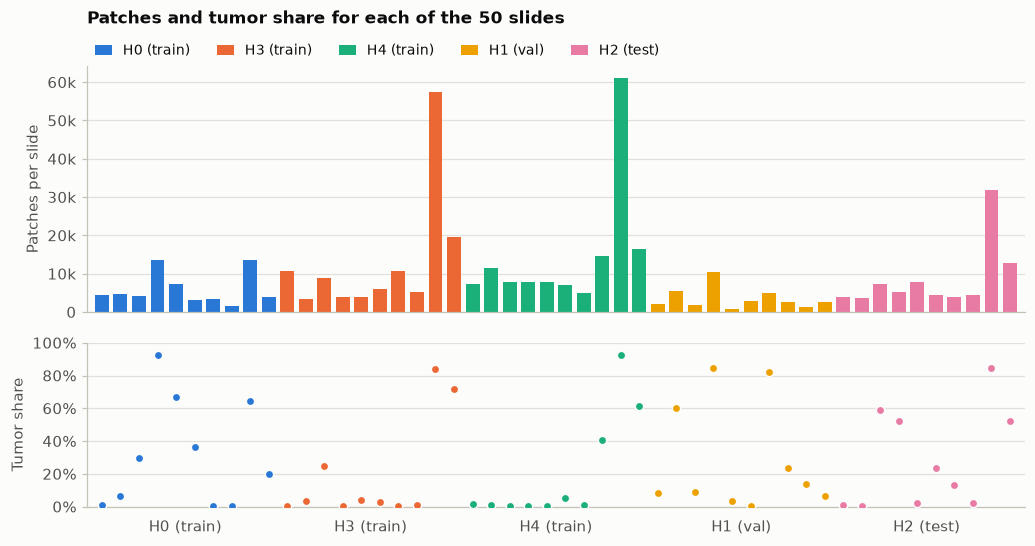

In [6]:
slides = (
    meta.groupby("slide")
    .agg(hospital=("hospital", "first"), n_patches=("tumor", "size"), n_tumor=("tumor", "sum"), tumor_fraction=("tumor", "mean"))
    .reset_index()
)
slides["role"] = slides.hospital.map(ROLE)
slides["order"] = slides.hospital.map(HOSPITALS.index)
slides = slides.sort_values(["order", "slide"]).drop(columns="order").reset_index(drop=True)
slides.to_csv(TABLE_DIR / "slides.csv", index=False)

x = np.arange(len(slides))
colors = slides.hospital.map(COLOR)
fig, (ax_n, ax_t) = plt.subplots(
    2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 2], "hspace": 0.15}
)
for h in HOSPITALS:
    own = (slides.hospital == h).to_numpy()
    ax_n.bar(x[own], slides.n_patches[own], width=0.75, color=COLOR[h], label=NAME[h])
    ax_t.scatter(x[own], slides.tumor_fraction[own], s=30, color=COLOR[h], edgecolor=SURFACE, linewidth=1, zorder=3)
    ax_t.text(x[own].mean(), -0.08, NAME[h], ha="center", va="top", color=INK_SOFT,
              transform=ax_t.get_xaxis_transform())
ax_n.set_title("Patches and tumor share for each of the 50 slides", pad=28)
ax_n.set_ylabel("Patches per slide")
ax_n.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}k" if v else "0"))
ax_n.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9, handlelength=1.2, borderaxespad=0.2)
ax_t.set_ylabel("Tumor share")
ax_t.set_ylim(0, 1)
ax_t.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_t.set_xticks([])
ax_t.set_xlim(-0.8, len(slides) - 0.2)
fig.savefig(FIG_DIR / "02_slides.png")
plt.show()

Tumor patches are concentrated in a few slides: the 50% class balance of each hospital hides
very few independent tumor examples. Few independent sources of signal is one reason why results vary
a lot from one training seed to another.

In [7]:
concentration = {}
for h in HOSPITALS:
    own = slides[slides.hospital == h]
    shares = (own.n_tumor / own.n_tumor.sum()).sort_values(ascending=False)
    concentration[NAME[h]] = {
        "slides with >= 1% tumor": int((own.tumor_fraction >= 0.01).sum()),
        "tumor patches from top slide": shares.iloc[0],
        "tumor patches from top 2 slides": shares.iloc[:2].sum(),
    }
concentration = pd.DataFrame.from_dict(concentration, orient="index")
concentration.to_csv(TABLE_DIR / "tumor_concentration_by_hospital.csv")
concentration.style.format({
    "slides with >= 1% tumor": "{:d}",
    "tumor patches from top slide": "{:.0%}",
    "tumor patches from top 2 slides": "{:.0%}",
})

,slides with >= 1% tumor,tumor patches from top slide,tumor patches from top 2 slides
H0 (train),7,43%,72%
H3 (train),7,74%,96%
H4 (train),6,77%,91%
H1 (val),9,50%,74%
H2 (test),8,63%,79%


## 3. What patches look like in each hospital

Random patches (fixed seed). The dashed square is the central 32×32 region: the label says whether
it contains tumor tissue, so tumor can be present at the border of a "non-tumor" patch.

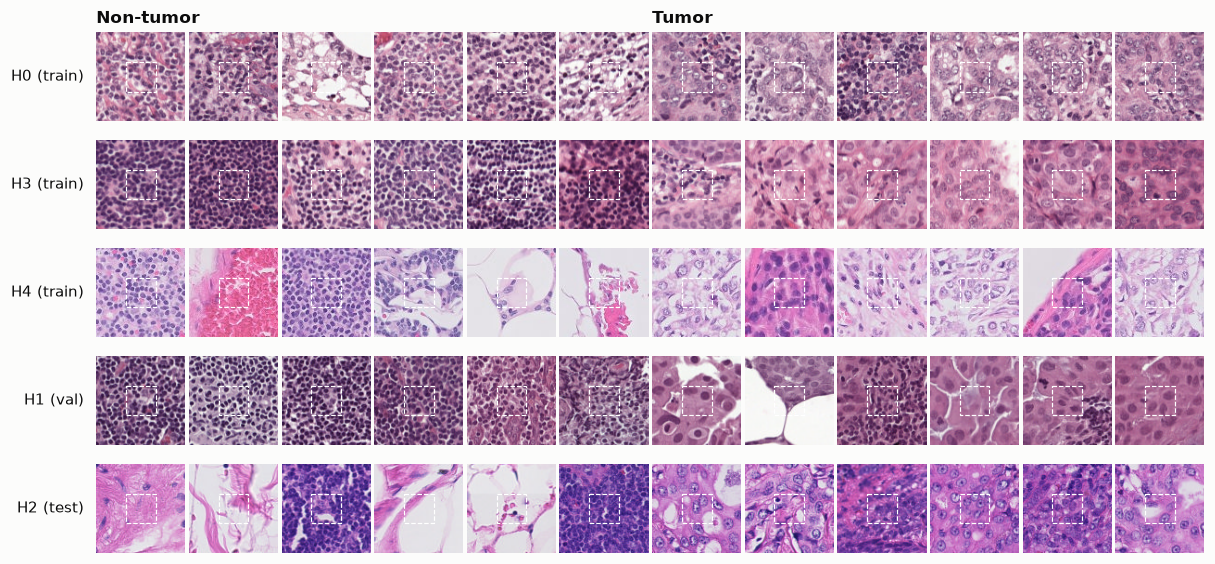

In [8]:
rng = np.random.default_rng(SEED)
N_PER_CLASS = 6
fig, axes = plt.subplots(
    len(HOSPITALS), 2 * N_PER_CLASS, figsize=(13, 6.3), gridspec_kw={"wspace": 0.04, "hspace": 0.06}
)
for row, h in enumerate(HOSPITALS):
    for label in (0, 1):
        pool = meta.index[(meta.hospital == h) & (meta.tumor == label)]
        for k, index in enumerate(rng.choice(pool, size=N_PER_CLASS, replace=False)):
            ax = axes[row, label * N_PER_CLASS + k]
            ax.imshow(dataset.get_input(int(index)))
            ax.add_patch(Rectangle((31.5, 31.5), 32, 32, fill=False, edgecolor="white", linewidth=0.8, linestyle="--"))
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(False)
    axes[row, 0].set_ylabel(NAME[h], rotation=0, ha="right", va="center", color=INK, labelpad=8)
axes[0, 0].set_title("Non-tumor")
axes[0, N_PER_CLASS].set_title("Tumor")
fig.savefig(FIG_DIR / "01_examples_by_hospital.png")
plt.show()

## 4. Stain color by hospital

H&E slides use two dyes: **hematoxylin** (purple-blue, binds nuclei) and **eosin** (pink, cytoplasm and
stroma). `rgb2hed` converts RGB into the concentration of each dye (Ruifrok & Johnston color deconvolution).

Two precautions:
- **Tissue only.** White background would dilute the averages. A pixel counts as tissue if its optical
  density is at least 0.15 in every channel (the criterion of Macenko et al., 2009, reused in Phase 4).
- **Balanced classes.** Tumor patches are more purple (dense nuclei). To compare hospitals and not tumor
  rates, we sample 1,000 tumor and 1,000 non-tumor patches per hospital.

In [9]:
OD_THRESHOLD = 0.15
MIN_TISSUE_PIXELS = 50  # below this, the patch is (almost) background
N_SAMPLE = 1000         # per hospital and per class


def color_features(image):
    rgb = np.asarray(image, dtype=np.float64) / 255.0
    # Optical density: stained tissue absorbs light, white background does not.
    od = -np.log(np.clip(rgb, 1 / 255, 1.0))
    tissue = np.all(od >= OD_THRESHOLD, axis=2)
    if tissue.sum() < MIN_TISSUE_PIXELS:
        return None
    hed = rgb2hed(rgb)[tissue]
    red, green, blue = rgb[tissue].mean(axis=0)
    return {
        "tissue_fraction": tissue.mean(),
        "red": red, "green": green, "blue": blue,
        "hematoxylin": hed[:, 0].mean(), "eosin": hed[:, 1].mean(),
    }


rng = np.random.default_rng(SEED)
rows = []
for h in HOSPITALS:
    for label in (0, 1):
        pool = meta.index[(meta.hospital == h) & (meta.tumor == label)]
        for index in rng.choice(pool, size=N_SAMPLE, replace=False):
            features = color_features(dataset.get_input(int(index)))
            if features is not None:
                rows.append({"index": int(index), "hospital": h, "slide": int(meta.slide[index]), "tumor": label, **features})
colors_df = pd.DataFrame(rows)
colors_df.to_csv(TABLE_DIR / "color_features_sample.csv", index=False)
print(f"{len(colors_df):,} patches kept out of {len(HOSPITALS) * 2 * N_SAMPLE:,} (the others are almost only background)")

medians = colors_df.groupby("hospital")[["hematoxylin", "eosin", "red", "green", "blue", "tissue_fraction"]].median()
medians = medians.reindex(HOSPITALS)
medians.index = [NAME[h] for h in HOSPITALS]
medians.to_csv(TABLE_DIR / "color_medians_by_hospital.csv")
medians.round(3)

9,999 patches kept out of 10,000 (the others are almost only background)


,hematoxylin,eosin,red,green,blue,tissue_fraction
H0 (train),0.032,0.011,0.683,0.523,0.643,0.806
H3 (train),0.030,0.022,0.669,0.431,0.583,0.902
H4 (train),0.027,0.011,0.745,0.598,0.760,0.482
H1 (val),0.047,0.015,0.580,0.408,0.559,0.975
H2 (test),0.045,0.031,0.646,0.410,0.713,0.864


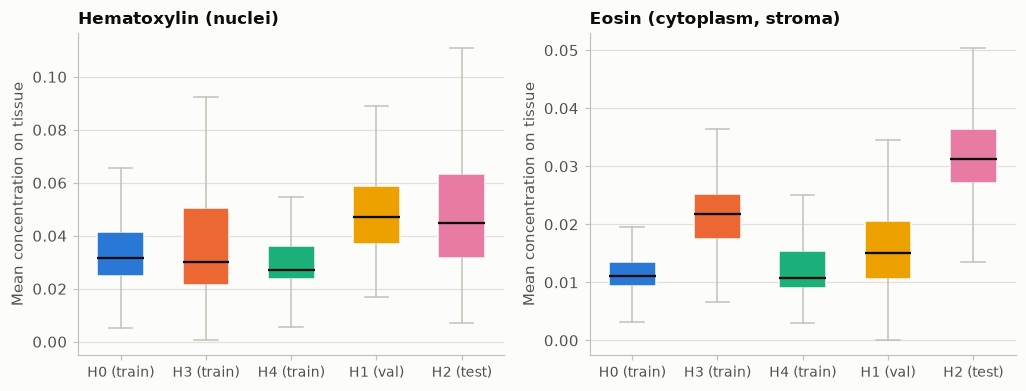

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
channels = [("hematoxylin", "Hematoxylin (nuclei)"), ("eosin", "Eosin (cytoplasm, stroma)")]
for ax, (channel, title) in zip(axes, channels):
    data = [colors_df.loc[colors_df.hospital == h, channel] for h in HOSPITALS]
    parts = ax.boxplot(
        data, patch_artist=True, widths=0.55, showfliers=False,
        medianprops={"color": INK, "linewidth": 1.5}, whiskerprops={"color": AXIS}, capprops={"color": AXIS},
    )
    for box, h in zip(parts["boxes"], HOSPITALS):
        box.set_facecolor(COLOR[h])
        box.set_edgecolor(SURFACE)
    ax.set_xticks(range(1, len(HOSPITALS) + 1), [NAME[h] for h in HOSPITALS], fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("Mean concentration on tissue")
fig.savefig(FIG_DIR / "03_stain_by_hospital.png")
plt.show()

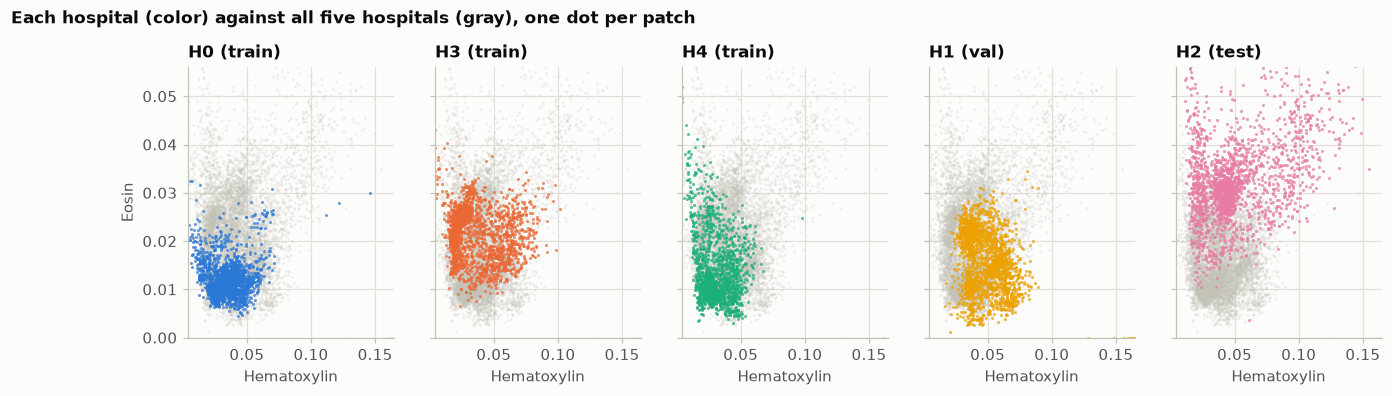

In [11]:
fig, axes = plt.subplots(1, len(HOSPITALS), figsize=(14, 3.2), sharex=True, sharey=True)
# Axis limits: wide enough for the 99th percentile of every hospital, so that
# a handful of extreme patches (e.g. ink or folds) does not squash the plot.
x_lim = (colors_df.hematoxylin.quantile(0.002), colors_df.groupby("hospital").hematoxylin.quantile(0.99).max())
y_lim = (colors_df.eosin.quantile(0.002), colors_df.groupby("hospital").eosin.quantile(0.99).max())
for ax, h in zip(axes, HOSPITALS):
    ax.scatter(colors_df.hematoxylin, colors_df.eosin, s=3, color=AXIS, alpha=0.25, linewidths=0, rasterized=True)
    own = colors_df[colors_df.hospital == h]
    ax.scatter(own.hematoxylin, own.eosin, s=4, color=COLOR[h], alpha=0.7, linewidths=0, rasterized=True)
    ax.set_title(NAME[h])
    ax.set_xlabel("Hematoxylin")
    ax.grid(True, axis="both")
axes[0].set_xlim(x_lim)
axes[0].set_ylim(y_lim)
axes[0].set_ylabel("Eosin")
fig.suptitle("Each hospital (color) against all five hospitals (gray), one dot per patch", x=0.01, ha="left",
             fontsize=11, fontweight="bold", y=1.04)
fig.savefig(FIG_DIR / "04_stain_space_by_hospital.png")
plt.show()

## 5. Can color alone identify the hospital?

A logistic regression gets only 5 numbers per patch (mean R, G, B, hematoxylin, eosin on tissue) and
must predict the hospital. Chance level is 20% (5 hospitals, balanced sample).

Cross-validation is **grouped by slide**: all patches of a slide are in the same fold. For comparison,
the same model is also evaluated with folds that ignore slides, to measure how much a slide-level leak
inflates a score.

In [12]:
FEATURES = ["red", "green", "blue", "hematoxylin", "eosin"]
X, y, groups = colors_df[FEATURES], colors_df.hospital, colors_df.slide
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
by_slide = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
by_patch = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores_slide = cross_val_score(model, X, y, groups=groups, cv=by_slide, scoring="balanced_accuracy")
scores_patch = cross_val_score(model, X, y, cv=by_patch, scoring="balanced_accuracy")
predicted = cross_val_predict(model, X, y, groups=groups, cv=by_slide)
recall = pd.Series({NAME[h]: (predicted[y == h] == h).mean() for h in HOSPITALS}, name="recall (slide-grouped CV)")

result = {
    "task": "predict the hospital from 5 color features of tissue pixels",
    "n_patches": int(len(colors_df)),
    "chance_level": 1 / len(HOSPITALS),
    "balanced_accuracy_slide_grouped": {"mean": scores_slide.mean(), "std": scores_slide.std(), "folds": scores_slide.tolist()},
    "balanced_accuracy_patch_level": {"mean": scores_patch.mean(), "std": scores_patch.std(), "folds": scores_patch.tolist()},
    "recall_by_hospital": recall.to_dict(),
}
(TABLE_DIR / "hospital_from_color.json").write_text(json.dumps(result, indent=2) + "\n")
print(f"Balanced accuracy, folds grouped by slide: {scores_slide.mean():.1%} ± {scores_slide.std():.1%}")
print(f"Balanced accuracy, folds ignoring slides:  {scores_patch.mean():.1%} ± {scores_patch.std():.1%}")
print(f"Chance level: {1 / len(HOSPITALS):.0%}")
recall.to_frame().style.format("{:.1%}")

Balanced accuracy, folds grouped by slide: 71.3% ± 13.7%
Balanced accuracy, folds ignoring slides:  76.5% ± 1.3%
Chance level: 20%


,recall (slide-grouped CV)
H0 (train),78.3%
H3 (train),65.1%
H4 (train),87.6%
H1 (val),47.9%
H2 (test),89.7%


## Key findings

Every number below comes from a file in `results/tables/` written by this notebook.

1. **Classes are balanced by design.** About 50% of patches are tumor in every hospital and split
   (exactly 50.0% in `val` and `test`). A model that always gives the same answer scores 50%.
   (`patches_by_hospital_split.csv`)
2. **Training hospitals are unevenly represented.** Of the 302,436 training patches, H0 provides 17.7%,
   H3 38.7% and H4 43.7%.
3. **`id_val` shares all 30 of its slides with `train`**, while no `val`/`test` slide appears in `train`.
   `id_val` accuracy is therefore an optimistic estimate, even for the training hospitals.
4. **Tumor patches come from very few slides.** In H3 and H4, the two largest slides hold 96% and 91% of the
   tumor patches (`tumor_concentration_by_hospital.csv`). Few independent sources of tumor examples is a
   plausible reason for the seed-to-seed variance reported by the WILDS authors.
5. **The test hospital is stained differently.** On tissue, the middle 50% of H2 patches has an eosin
   concentration of 0.027–0.037, entirely above the middle 50% of every training hospital (at most 0.017–0.025,
   H3) (`color_features_sample.csv`). The model will have to extrapolate in color.
6. **Color alone identifies the hospital.** Five color numbers give 71.3% ± 13.7% balanced accuracy for
   predicting the hospital (chance: 20%), with folds grouped by slide. H2 is the most recognizable
   (recall 89.7%), consistent with the WILDS paper, which chose it as the most visually distinctive hospital
   (`hospital_from_color.json`). A CNN can use color as a shortcut: this is what the Phase 4 color
   experiments (planned before this exploration) will test.
7. **Slide leakage inflates scores and hides variance.** With folds that ignore slides, the same model scores
   76.5% ± 1.3%: 5 points higher and a ten times smaller spread. The same mechanism makes `id_val` optimistic.

**Caveats.** Color statistics use a balanced sample of 2,000 patches per hospital and average over tissue
pixels only. `rgb2hed` uses a fixed, generic stain matrix (Ruifrok & Johnston), not the true stain vectors
of each hospital: the H and E values are comparable between hospitals, not absolute concentrations.